# PyPolSARpro check (venv, no conda)
Verifies that PyPolSARpro is installed and working in `.venv_biomass`. It needs no credentials and no downloads: it builds a small synthetic scattering matrix and runs the same calls as the MAAP *Getting Started with PyPolSARpro* notebook.

`polsarpro` is not on PyPI, so it is installed from GitHub. Run once in a terminal, from the repo root:
```powershell
.\.venv_biomass\Scripts\python.exe -m pip install xarray dask bottleneck netcdf4 rioxarray zarr
.\.venv_biomass\Scripts\python.exe -m pip install --no-deps --ignore-requires-python "git+https://github.com/satim-co/PolSARpro.git@main"
```
`--ignore-requires-python` is needed because the package declares Python `>=3.12,<3.13`; `--no-deps` skips its `gdal` dependency, which has no Windows wheel on PyPI and is never imported by the code.

## 1. Imports and versions

In [1]:
import sys
import tempfile
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from dask.diagnostics import ProgressBar
from polsarpro.decompositions import freeman, h_a_alpha

print("python   ", sys.version.split()[0])
print("interpreter", sys.executable)
for pkg in ("polsarpro", "numpy", "xarray", "dask", "netCDF4"):
    print(f"{pkg:<10}", version(pkg))

python    3.13.15
interpreter <project folder>\.venv_biomass\Scripts\python.exe
polsarpro  2026.6.0
numpy      2.5.3
xarray     2026.9.0
dask       2026.8.0
netCDF4    1.7.4


## 2. Synthetic scattering matrix
A 256 x 256 image with two known targets, so the expected answer is known in advance:
- **left half**: trihedral-like, `hh = vv` (odd bounce / surface scattering)
- **right half**: dihedral-like, `hh = -vv` (double bounce)

The dataset has the layout PolSARpro expects for an `S` matrix: variables `hh`, `hv`, `vh`, `vv` and the attribute `poltype="S"`.

In [2]:
N = 256
rng = np.random.default_rng(0)
dims = ("y", "x")


def noise(scale):
    return scale * (rng.standard_normal((N, N)) + 1j * rng.standard_normal((N, N)))


sign = np.where(np.arange(N) < N // 2, 1.0, -1.0)[None, :]
amp = 1.0 + noise(0.3)
hv = noise(0.05)

S = xr.Dataset(
    {
        "hh": (dims, (amp + noise(0.05)).astype("complex64")),
        "hv": (dims, hv.astype("complex64")),
        "vh": (dims, hv.astype("complex64")),
        "vv": (dims, (sign * amp + noise(0.05)).astype("complex64")),
    },
    coords={"y": np.arange(N), "x": np.arange(N)},
    attrs={"poltype": "S", "description": "Scattering matrix"},
).chunk(64)
S

<xarray.Dataset> Size: 2MB
Dimensions:  (y: 256, x: 256)
Coordinates:
  * y        (y) int64 2kB 0 1 2 3 4 5 6 7 8 ... 248 249 250 251 252 253 254 255
  * x        (x) int64 2kB 0 1 2 3 4 5 6 7 8 ... 248 249 250 251 252 253 254 255
Data variables:
    hh       (y, x) complex64 524kB dask.array<chunksize=(64, 64), meta=np.ndarray>
    hv       (y, x) complex64 524kB dask.array<chunksize=(64, 64), meta=np.ndarray>
    vh       (y, x) complex64 524kB dask.array<chunksize=(64, 64), meta=np.ndarray>
    vv       (y, x) complex64 524kB dask.array<chunksize=(64, 64), meta=np.ndarray>
Attributes:
    poltype:      S
    description:  Scattering matrix

## 3. Freeman-Durden decomposition
Same call as the MAAP notebook: compute lazily with dask, write to NetCDF, read it back.

In [3]:
out_file = Path(tempfile.mkdtemp()) / "freeman_synthetic.nc"

with ProgressBar():
    freeman(S, [7, 7]).to_netcdf(out_file)

out = xr.open_dataset(out_file).load()
out

[########################################] | 100% Completed | 534.76 ms


<xarray.Dataset> Size: 791kB
Dimensions:  (y: 256, x: 256)
Coordinates:
  * y        (y) int64 2kB 0 1 2 3 4 5 6 7 8 ... 248 249 250 251 252 253 254 255
  * x        (x) int64 2kB 0 1 2 3 4 5 6 7 8 ... 248 249 250 251 252 253 254 255
Data variables:
    odd      (y, x) float32 262kB 0.8075 0.9826 1.253 ... 0.7723 0.7723 0.7723
    double   (y, x) float32 262kB 0.7723 0.7723 0.7723 ... 1.216 0.974 0.7723
    volume   (y, x) float32 262kB 0.7723 0.7723 0.7723 ... 0.7723 0.7723 0.7723
Attributes:
    poltype:      freeman
    description:  Results of the Freeman-Durden decomposition.

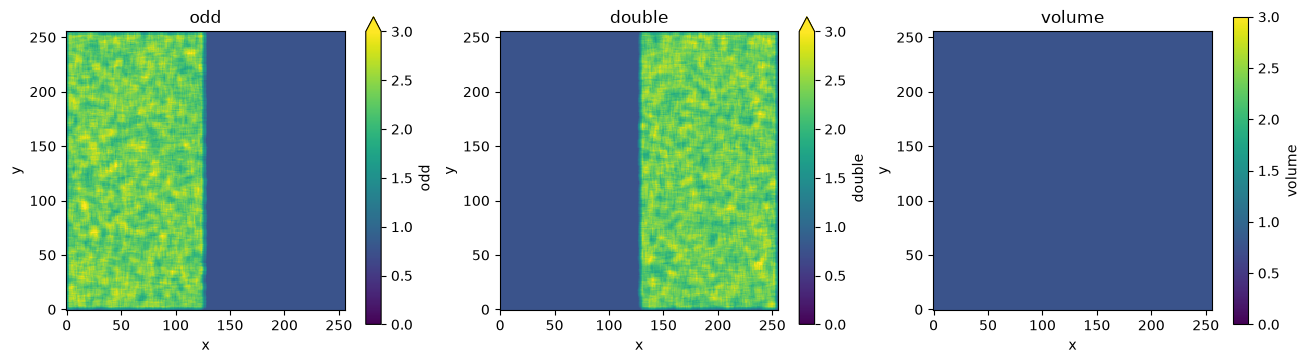

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for ax, name in zip(axes, ("odd", "double", "volume")):
    out[name].plot.imshow(ax=ax, vmin=0, vmax=3, cmap="viridis")
    ax.set_title(name)
    ax.set_aspect("equal")
plt.show()

## 4. H/A/Alpha decomposition
The alpha angle should be close to 0 deg on the trihedral half and close to 90 deg on the dihedral half.

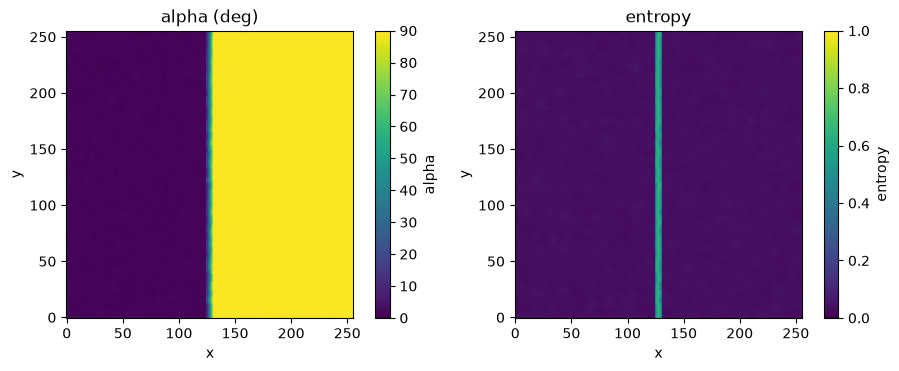

In [5]:
haa = h_a_alpha(S, boxcar_size=[7, 7]).compute()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), constrained_layout=True)
haa.alpha.plot.imshow(ax=axes[0], vmin=0, vmax=90, cmap="viridis")
haa.entropy.plot.imshow(ax=axes[1], vmin=0, vmax=1, cmap="viridis")
for ax, name in zip(axes, ("alpha (deg)", "entropy")):
    ax.set_title(name)
    ax.set_aspect("equal")
plt.show()

## 5. Checks
If this cell prints `PyPolSARpro OK`, the install works. Note that PolSARpro clamps each Freeman component to the minimum span of the image, so the non-dominant components sit on that floor instead of going to zero.

In [6]:
# Stay away from the image border and from the boundary between the two halves
left = dict(x=slice(10, N // 2 - 10))
right = dict(x=slice(N // 2 + 10, N - 10))

for name, sel in (("trihedral half", left), ("dihedral half", right)):
    means = {v: round(float(out[v].isel(**sel).mean()), 3) for v in ("odd", "double", "volume")}
    print(f"{name:<15} freeman {means}  alpha {float(haa.alpha.isel(**sel).mean()):.1f} deg")

assert all(np.isfinite(out[v]).all() for v in out.data_vars), "non-finite values in the Freeman output"
assert out.odd.isel(**left).mean() > 2 * out.double.isel(**left).mean(), "odd bounce should dominate on the left"
assert out.double.isel(**right).mean() > 2 * out.odd.isel(**right).mean(), "double bounce should dominate on the right"
assert haa.alpha.isel(**left).mean() < 20, "alpha should be near 0 deg on the trihedral half"
assert haa.alpha.isel(**right).mean() > 70, "alpha should be near 90 deg on the dihedral half"

print("PyPolSARpro OK")

trihedral half  freeman {'odd': 2.333, 'double': 0.772, 'volume': 0.772}  alpha 1.2 deg
dihedral half   freeman {'odd': 0.772, 'double': 2.32, 'volume': 0.772}  alpha 89.5 deg
PyPolSARpro OK
